In [3]:
%pip install -q optuna

In [4]:
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

import optuna

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
# seeding for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# configuration
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

In [6]:
# # 20,640 samples, with 8 input features per sample
# target = median house value in $100,000s
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print(X.shape, y.shape)

(20640, 8) (20640,)


In [7]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250


In [8]:
X.isna().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0


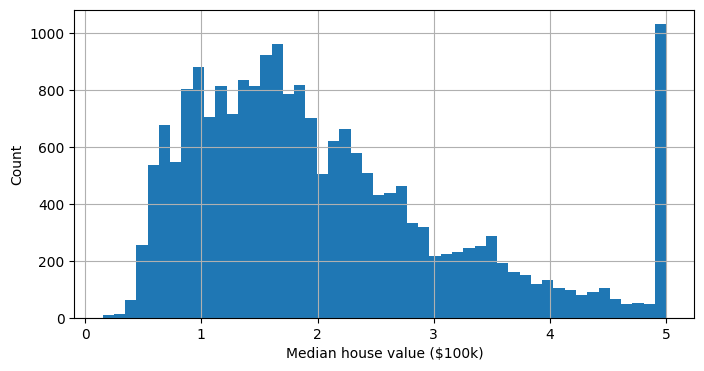

In [9]:
y.hist(bins=50, figsize=(8, 4))
plt.xlabel("Median house value ($100k)")
plt.ylabel("Count")
plt.show()

In [10]:
X_train_full, X_test_raw, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42
)

print("Train:     ", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:      ", X_test_raw.shape)

Train:      (12384, 8)
Validation: (4128, 8)
Test:       (4128, 8)


In [11]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

In [12]:
def model_build(num_layers=2,num_units=64,dropout_rate=0.0,learning_rate=1e-3):
  model = keras.Sequential()
  #input layer
  model.add(keras.layers.Input(shape=(X_train.shape[1],)))

  #hidden layer

  for _ in range(num_layers):
    model.add(keras.layers.Dense(num_units,activation="relu"))
    if dropout_rate > 0:
      model.add(keras.layers.Dropout(dropout_rate))

  #output layer
  model.add(keras.layers.Dense(1))


  optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(loss="mse",optimizer=optimizer,metrics =[keras.metrics.RootMeanSquaredError(name="rmse")])

  return model


In [13]:
baseline_model = model_build()

early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

history = baseline_model.fit(
    X_train,y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val,y_val),
    callbacks=[early_stopping],
    verbose =0)

print(f"trained for {len(history.history['loss'])} epochs")

trained for 26 epochs


In [14]:
#evaluating the test set
baseline_pred =baseline_model.predict(X_test, verbose=0)
baseline_rmse = np.sqrt(mean_squared_error(y_test,baseline_pred))
baseline_r2 = r2_score(y_test,baseline_pred)

print(f"Baseline test RMSE: {baseline_rmse:.4f}  (≈ ${baseline_rmse*100:.0f}k average error)")
print(f"Baseline test R²:   {baseline_r2:.4f}")

Baseline test RMSE: 0.5370  (≈ $54k average error)
Baseline test R²:   0.7799


In [15]:
#hyperparameter tuning with optuna

def objective(trial):

    # Optuna picks a value for each hyperparameter from these ranges
  num_layers = trial.suggest_int("num_layers", 1, 3)
  num_units     = trial.suggest_int("num_units", 32, 256, log=True)
  dropout_rate  = trial.suggest_float("dropout_rate", 0.0, 0.4)
  learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
  batch_size    = trial.suggest_categorical("batch_size", [32, 64, 128])

  model= model_build(num_layers, num_units, dropout_rate, learning_rate)

  early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)

  history = model.fit(
    X_train,y_train,
    epochs=50,
    batch_size=batch_size,
    validation_data=(X_val,y_val),
    callbacks=[early_stopping],
    verbose =0)

  best_epoch = int(np.argmin(history.history["val_loss"])) + 1
  trial.set_user_attr("best_epoch", best_epoch)

  # score this trial on the validation set
  val_pred = model.predict(X_val, verbose=0)

  return np.sqrt(mean_squared_error(y_val, val_pred))



In [16]:
#running the search
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="minimize",sampler = optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=10,show_progress_bar=True)


print(f"Best validation RMSE: {study.best_value:.4f}")
print("Best hyperparameters:")
for name, value in study.best_params.items():
    print(f"  {name}: {value}")

  0%|          | 0/10 [00:00<?, ?it/s]

Best validation RMSE: 0.5134
Best hyperparameters:
  num_layers: 2
  num_units: 231
  dropout_rate: 0.292797576724562
  learning_rate: 0.0015751320499779737
  batch_size: 32


In [17]:
best = study.best_params
best_epoch = study.best_trial.user_attrs["best_epoch"]

best_model = model_build(
    num_layers=best["num_layers"],
    num_units=best["num_units"],
    dropout_rate=best["dropout_rate"],
    learning_rate=best["learning_rate"],
)

# train on train + validation, for exactly best_epoch epochs
best_model.fit(
    np.vstack([X_train, X_val]),
    np.concatenate([y_train, y_val]),
    epochs=best_epoch,
    batch_size=best["batch_size"],
    verbose=0,
)

print(f"Retrained for {best_epoch} epochs on train + validation")

Retrained for 43 epochs on train + validation


In [18]:
best_pred = best_model.predict(X_test, verbose=0)

best_rmse = np.sqrt(mean_squared_error(y_test, best_pred))
best_r2   = r2_score(y_test, best_pred)

print(f"{'':12}{'RMSE':>8}{'R²':>8}")
print(f"{'Baseline':<12}{baseline_rmse:>8.4f}{baseline_r2:>8.4f}")
print(f"{'Optuna':<12}{best_rmse:>8.4f}{best_r2:>8.4f}")

                RMSE      R²
Baseline      0.5370  0.7799
Optuna        0.5201  0.7936
